In [138]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [139]:
df = pd.read_csv("/content/spam.csv", encoding='latin-1')

In [140]:
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [141]:
df.shape

(5572, 5)

In [142]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [143]:
df.drop(columns=["Unnamed: 2","Unnamed: 3","Unnamed: 4"],inplace=True)

In [144]:
df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [145]:
df.rename(columns={'v1':'Target','v2':'Text'},inplace=True)

In [146]:
df.head()

,Target,Text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [147]:
from sklearn.preprocessing import LabelEncoder
encoder=LabelEncoder()

In [148]:
df['Target']=encoder.fit_transform(df['Target'])

In [149]:
df.head()

,Target,Text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [150]:
df.isnull().sum()

,0
Target,0
Text,0


In [151]:
df.duplicated().sum()

np.int64(403)

In [152]:
df=df.drop_duplicates(keep='first')

In [153]:
df.duplicated().sum()

np.int64(0)

In [154]:
df.shape

(5169, 2)

In [155]:
#EDA
df['Target'].value_counts()

,count
Target,
0,4516
1,653


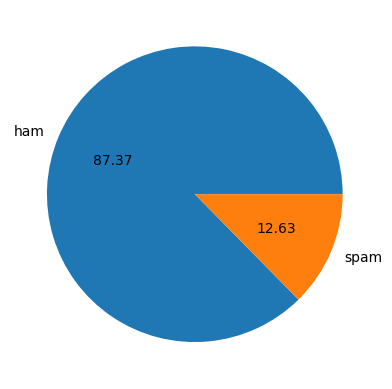

In [156]:
plt.pie(df['Target'].value_counts(), labels=['ham', 'spam'], autopct="%0.2f")
plt.show()#---- Data is imbalanced

In [157]:
import nltk

In [158]:
nltk.download('punkt')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [159]:
df['num_char']=df['Text'].apply(len)

In [160]:
df.head()

,Target,Text,num_char
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61


In [161]:
import nltk
nltk.download('punkt_tab')

# Num of words
df['num_word']=df['Text'].apply(lambda x:len(nltk.word_tokenize(x)))

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [162]:
df.head()

,Target,Text,num_char,num_word
0,0,"Go until jurong point, crazy.. Available only ...",111,24
1,0,Ok lar... Joking wif u oni...,29,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37
3,0,U dun say so early hor... U c already then say...,49,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15


In [163]:
# sent words
df['sent']=df['Text'].apply(lambda x:len(nltk.sent_tokenize(x)))

In [164]:
df.head()

,Target,Text,num_char,num_word,sent
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1


In [165]:
df[['num_char','num_word','sent']].describe()

,num_char,num_word,sent
count,5169.000000,5169.000000,5169.000000
mean,78.977945,18.455794,1.965564
std,58.236293,13.324758,1.448541
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


In [166]:
#Ham
df[df['Target']==0][['num_char','num_word','sent']].describe()

,num_char,num_word,sent
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.123782,1.820195
std,56.358207,13.493970,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [167]:
#Spam
df[df['Target']==1][['num_char','num_word','sent']].describe()

,num_char,num_word,sent
count,653.000000,653.000000,653.000000
mean,137.891271,27.667688,2.970904
std,30.137753,7.008418,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


<Axes: xlabel='num_char', ylabel='Count'>

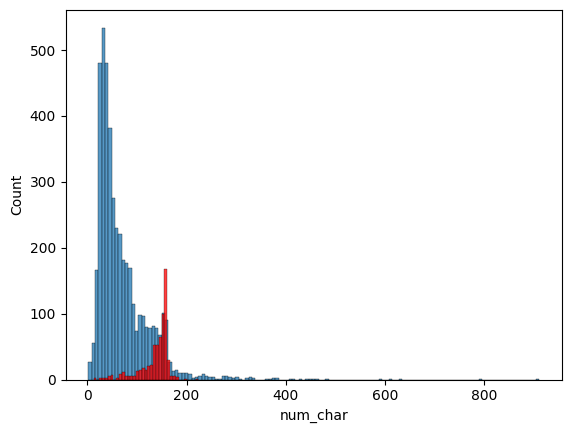

In [168]:
sns.histplot(df[df['Target']==0]['num_char'])#ham
sns.histplot(df[df['Target']==1]['num_char'],color='red')#spam


<Axes: xlabel='num_word', ylabel='Count'>

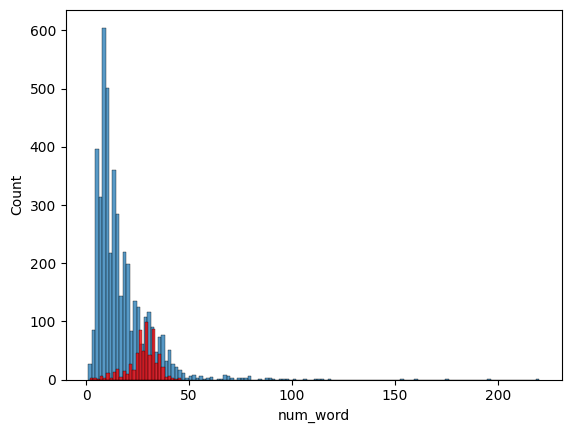

In [169]:
sns.histplot(df[df['Target']==0]['num_word'])#ham
sns.histplot(df[df['Target']==1]['num_word'],color='red')#spam


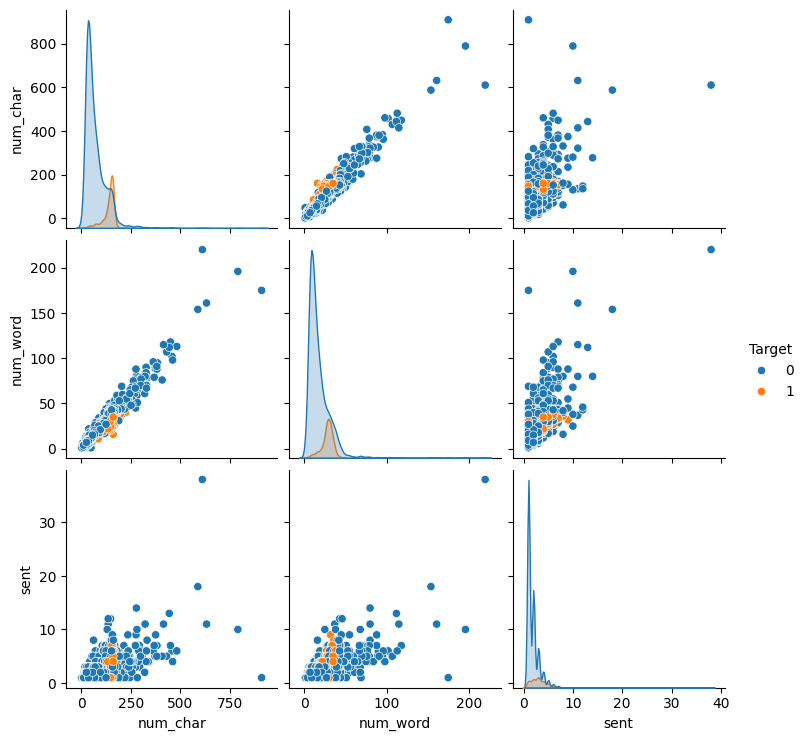

In [170]:
sns.pairplot(df,hue='Target')

In [171]:
df.corr(numeric_only=True)

,Target,num_char,num_word,sent
Target,1.000000,0.384717,0.262912,0.263939
num_char,0.384717,1.000000,0.965760,0.624139
num_word,0.262912,0.965760,1.000000,0.679971
sent,0.263939,0.624139,0.679971,1.000000


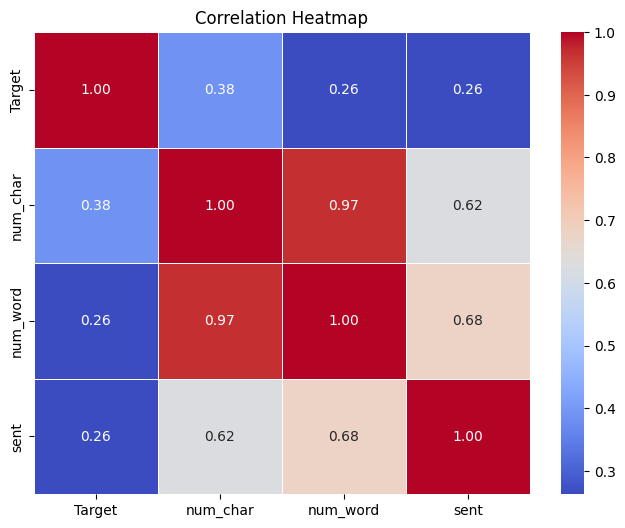

In [172]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

**This plot visually represents the correlation coefficients between your numeric columns:

Target (0 for Ham, 1 for Spam)
num_char (character count)
num_word (word count)
sent (sentence count)
Key Takeaways from the Heatmap:
High Collinearity: num_char and num_word have an extremely strong correlation of 0.97, meaning they contain very redundant information. For model training, we typically want to avoid using both features because they are almost perfectly collinear.
Spam Characteristics: The positive correlation of 0.38 between Target and num_char indicates that spam messages are moderately associated with longer text lengths (higher character counts) compared to ham messages.
**

In [174]:
#  Data preprocessing
#Lower Case
##Removing special char
#Removing stop words and punctuation
#stemming


In [175]:
import nltk
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
import string

# Download stopwords if not already done
nltk.download('stopwords')
ps = PorterStemmer()

def transform_text(text):
    # 1. Lowercase
    text = text.lower()

    # 2. Tokenization
    y = nltk.word_tokenize(text)

    # 3. Removing special characters
    tokens = []
    for i in y:
        if i.isalnum():
            tokens.append(i)

    # 4. Removing stop words and punctuation
    y = []
    stop_words = set(stopwords.words('english'))
    for i in tokens:
        if i not in stop_words and i not in string.punctuation:
            y.append(i)

    # 5. Stemming
    final_tokens = []
    for i in y:
        final_tokens.append(ps.stem(i))

    return " ".join(final_tokens)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [176]:
transform_text("I'm loved playing machine learning tasks! HI HOW ARE YOU %%%")

'love play machin learn task hi'

In [177]:
df['Transform_text']=df['Text'].apply(transform_text)

In [178]:
df.head()

,Target,Text,num_char,num_word,sent,Transform_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though


### Step-by-Step Explanation of Text Preprocessing (`transform_text`)

This function systematically cleans and prepares raw text for machine learning models. Here is how it processes text step-by-step:

1. **Convert to Lowercase**:
   - `text = text.lower()`
   - Standardizes the text. This ensures that the model treats words like `"Go"` and `"go"` as the exact same token.

2. **Tokenization**:
   - `y = nltk.word_tokenize(text)`
   - Breaks down the single continuous string of text into a list of individual words, punctuation marks, and symbols.

3. **Remove Special Characters**:
   - `for i in y: if i.isalnum(): tokens.append(i)`
   - Filters out raw punctuation characters or symbols (such as `%`, `@`, `!`) by checking if each character is alphanumeric (letters and numbers only).

4. **Remove Stop Words and Punctuation**:
   - `if i not in stop_words and i not in string.punctuation:`
   - Filters out words that appear frequently but carry very little unique information (e.g., `"the"`, `"is"`, `"are"`, `"you"`) using NLTK's English stop words set, along with any remaining punctuation symbols.

5. **Stemming**:
   - `final_tokens.append(ps.stem(i))`
   - Redundant prefixes/suffixes are chopped off to reduce words to their base grammatical root using the **Porter Stemmer**. For example, words like *"loved"*, *"loves"*, and *"loving"* all map down to *"love"*.

6. **Join Back to String**:
   - `return " ".join(final_tokens)`
   - Merges the processed list of token roots back into a single whitespace-separated string, making it ready for feature extraction (e.g., TF-IDF or Bag of Words).

In [179]:
from wordcloud import WordCloud
# Initialize the word cloud generator
wc = WordCloud(width=500, height=500, min_font_size=10, background_color='white')
# Generate word cloud for Spam messages (Target == 1)
spam_wc = wc.generate(df[df['Target'] == 1]['Transform_text'].str.cat(sep=" "))



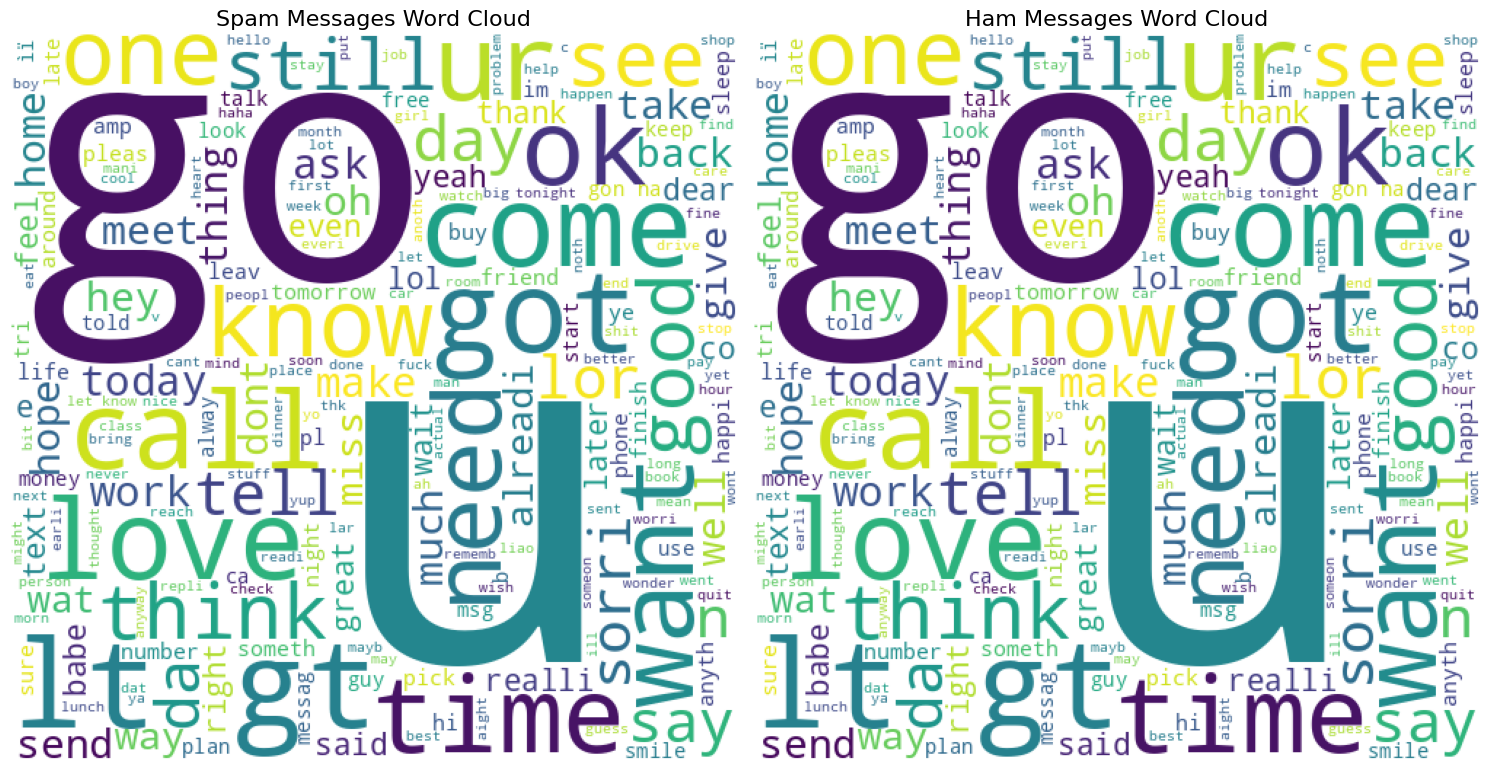

In [180]:
# Generate word cloud for Ham messages (Target == 0)
ham_wc = wc.generate(df[df['Target'] == 0]['Transform_text'].str.cat(sep=" "))

# Plot the Word Clouds
plt.figure(figsize=(15, 8))
# Spam Word Cloud
plt.subplot(1, 2, 1)
plt.imshow(spam_wc)
plt.title('Spam Messages Word Cloud', fontsize=16)
plt.axis('off')

# Ham Word Cloud
plt.subplot(1, 2, 2)
plt.imshow(ham_wc)
plt.title('Ham Messages Word Cloud', fontsize=16)
plt.axis('off')

plt.tight_layout()
plt.show()



**A Word Cloud is a visual representation of text data where the size of each word indicates its frequency or importance in the dataset.



In our spam classifier project, creating word clouds for both Spam and Ham (non-spam) messages is incredibly useful. It helps us see at a glance which words appear most frequently in spam messages (like "free", "call", "txt", "claim") versus ham messages.

**

In [181]:
spam_corpuss=[]
for msg in df[df['Target']==1]['Transform_text'].tolist():
  for word in msg.split():
    spam_corpuss.append(word)

In [182]:
len(spam_corpuss)

9939

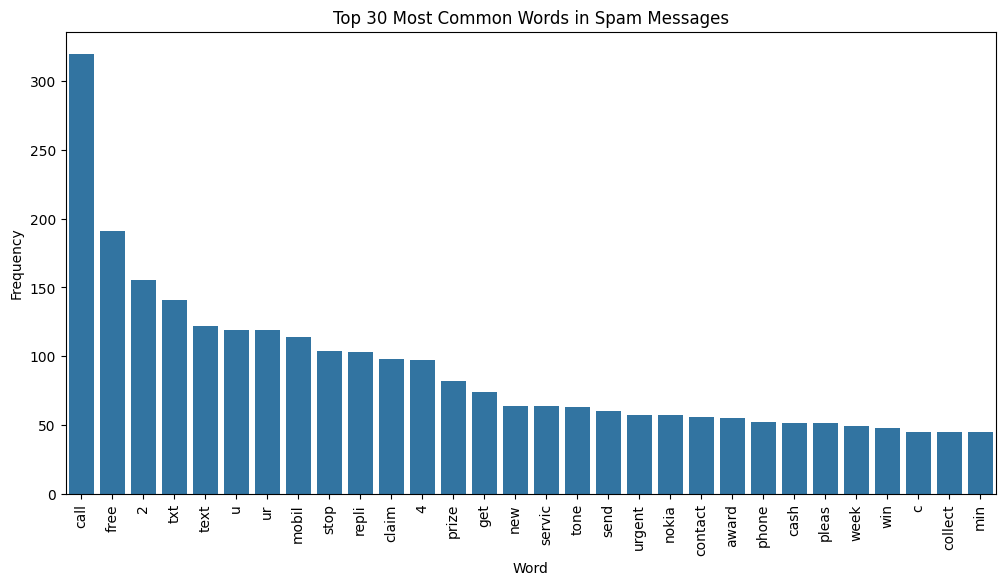

In [183]:
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create a DataFrame of the top 30 most common words
top_words_df = pd.DataFrame(Counter(spam_corpuss).most_common(30), columns=['Word', 'Frequency'])

# Plot the barplot specifying x and y clearly
plt.figure(figsize=(12, 6))
sns.barplot(x='Word', y='Frequency', data=top_words_df)
plt.xticks(rotation='vertical')
plt.title('Top 30 Most Common Words in Spam Messages')
plt.show()

In [184]:
ham_corpus = []
for msg in df[df['Target'] == 0]['Transform_text'].tolist():
  for word in msg.split():
    ham_corpus.append(word)

In [185]:
# Count total words in ham corpus
len(ham_corpus)

35404

/tmp/ipykernel_492/1879575895.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Word', y='Frequency', data=top_ham_words_df, palette='viridis')


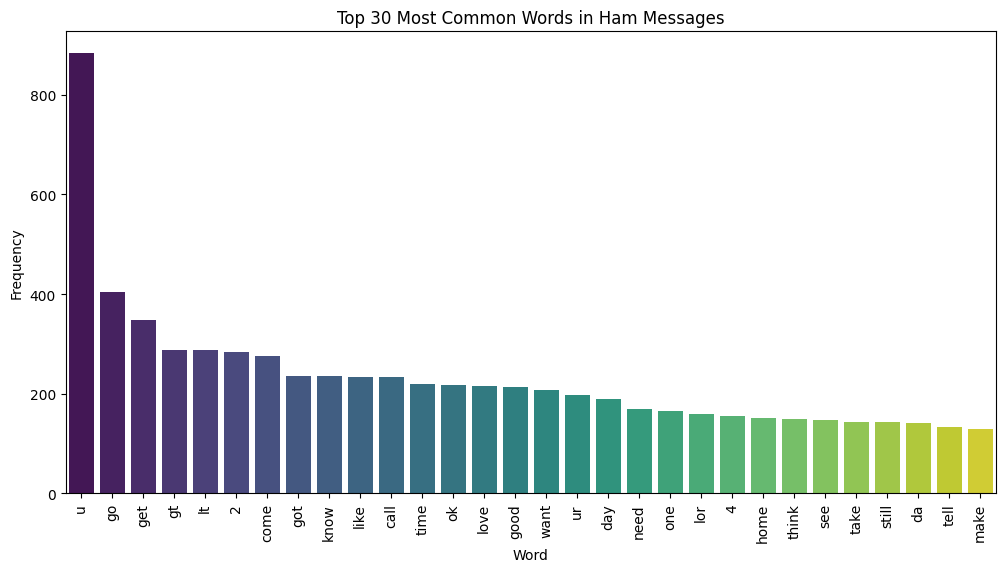

In [186]:
# Create a DataFrame of the top 30 most common words in ham
top_ham_words_df = pd.DataFrame(Counter(ham_corpus).most_common(30), columns=['Word', 'Frequency'])

# Plot the barplot specifying x and y clearly
plt.figure(figsize=(12, 6))
sns.barplot(x='Word', y='Frequency', data=top_ham_words_df, palette='viridis')
plt.xticks(rotation='vertical')
plt.title('Top 30 Most Common Words in Ham Messages')
plt.show()

In [187]:
# Model Buliding

In [188]:
from sklearn.feature_extraction.text import CountVectorizer
cv=CountVectorizer()

In [189]:
X=cv.fit_transform(df['Transform_text']).toarray()

In [190]:
X.shape

(5169, 6708)

In [191]:
# Extract target array y
y = df['Target'].values


In [192]:
y

array([0, 0, 1, ..., 0, 0, 0])

In [193]:
# Split data into training and test sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (4135, 6708)
X_test shape: (1034, 6708)


In [194]:
from sklearn.naive_bayes import GaussianNB,MultinomialNB,BernoulliNB
from sklearn.metrics import accuracy_score,confusion_matrix,precision_score

In [195]:
gnb=GaussianNB()
mnb=MultinomialNB()
bnb=BernoulliNB()

In [196]:
gnb.fit(X_train,y_train)
y_pred1=gnb.predict(X_test)
print(accuracy_score(y_test,y_pred1))
print(confusion_matrix(y_test,y_pred1))
print(precision_score(y_test,y_pred1))


0.8684719535783365
[[772 117]
 [ 19 126]]
0.5185185185185185


In [197]:
mnb.fit(X_train,y_train)
y_pred2=mnb.predict(X_test)
print(accuracy_score(y_test,y_pred2))
print(confusion_matrix(y_test,y_pred2))
print(precision_score(y_test,y_pred2))


0.9738878143133463
[[872  17]
 [ 10 135]]
0.8881578947368421


In [198]:
bnb.fit(X_train,y_train)
y_pred3=bnb.predict(X_test)
print(accuracy_score(y_test,y_pred3))
print(confusion_matrix(y_test,y_pred3))
print(precision_score(y_test,y_pred3))


0.9661508704061895
[[885   4]
 [ 31 114]]
0.9661016949152542


In [199]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TfidfVectorizer
tfidf = TfidfVectorizer(max_features=3000)

# Transform the preprocessed text
X_tfidf = tfidf.fit_transform(df['Transform_text']).toarray()

# Split the dataset using the TF-IDF features
X_train_tf, X_test_tf, y_train_tf, y_test_tf = train_test_split(X_tfidf, y, test_size=0.2, random_state=42)

# Re-initialize the Naive Bayes models
gnb_tf = GaussianNB()
mnb_tf = MultinomialNB()
bnb_tf = BernoulliNB()

# Train and evaluate Gaussian Naive Bayes
gnb_tf.fit(X_train_tf, y_train_tf)
y_pred1_tf = gnb_tf.predict(X_test_tf)
print("--- GaussianNB (TF-IDF) ---")
print("Accuracy :", accuracy_score(y_test_tf, y_pred1_tf))
print("Confusion:\n", confusion_matrix(y_test_tf, y_pred1_tf))
print("Precision:", precision_score(y_test_tf, y_pred1_tf))

# Train and evaluate Multinomial Naive Bayes
mnb_tf.fit(X_train_tf, y_train_tf)
y_pred2_tf = mnb_tf.predict(X_test_tf)
print("\n--- MultinomialNB (TF-IDF) ---")
print("Accuracy :", accuracy_score(y_test_tf, y_pred2_tf))
print("Confusion:\n", confusion_matrix(y_test_tf, y_pred2_tf))
print("Precision:", precision_score(y_test_tf, y_pred2_tf))

# Train and evaluate Bernoulli Naive Bayes
bnb_tf.fit(X_train_tf, y_train_tf)
y_pred3_tf = bnb_tf.predict(X_test_tf)
print("\n--- BernoulliNB (TF-IDF) ---")
print("Accuracy :", accuracy_score(y_test_tf, y_pred3_tf))
print("Confusion:\n", confusion_matrix(y_test_tf, y_pred3_tf))
print("Precision:", precision_score(y_test_tf, y_pred3_tf))

--- GaussianNB (TF-IDF) ---
Accuracy : 0.8626692456479691
Confusion:
 [[771 118]
 [ 24 121]]
Precision: 0.5062761506276151

--- MultinomialNB (TF-IDF) ---
Accuracy : 0.9729206963249516
Confusion:
 [[888   1]
 [ 27 118]]
Precision: 0.9915966386554622

--- BernoulliNB (TF-IDF) ---
Accuracy : 0.9729206963249516
Confusion:
 [[884   5]
 [ 23 122]]
Precision: 0.9606299212598425


In [200]:
# WE ARE THE CHOOSE TFDIF---> MULTINOMINALNB

In [201]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, BaggingClassifier, ExtraTreesClassifier, GradientBoostingClassifier

# Initialize multiple classifiers
svc = SVC(kernel='sigmoid', gamma=1.0)
knc = KNeighborsClassifier()
mnb = MultinomialNB()
dtc = DecisionTreeClassifier(max_depth=5)
lrc = LogisticRegression(solver='liblinear', penalty='l1')
rfc = RandomForestClassifier(n_estimators=50, random_state=2)
abc = AdaBoostClassifier(n_estimators=50, random_state=2)
bc = BaggingClassifier(n_estimators=50, random_state=2)
etc = ExtraTreesClassifier(n_estimators=50, random_state=2)
gbdt = GradientBoostingClassifier(n_estimators=50, random_state=2)

clfs = {
    'SVC': svc,
    'KN': knc,
    'NB': mnb,
    'DT': dtc,
    'LR': lrc,
    'RF': rfc,
    'AdaBoost': abc,
    'BgC': bc,
    'ETC': etc,
    'GBDT': gbdt
}

def train_classifier(clf, X_train, y_train, X_test, y_test):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    return accuracy, precision

# Evaluate all models
accuracy_scores = []
precision_scores = []

for name, clf in clfs.items():
    current_accuracy, current_precision = train_classifier(clf, X_train_tf, y_train_tf, X_test_tf, y_test_tf)

    print(f"For {name}:")
    print(f"  Accuracy  - {current_accuracy:.4f}")
    print(f"  Precision - {current_precision:.4f}\n")

    accuracy_scores.append(current_accuracy)
    precision_scores.append(current_precision)

For SVC:
  Accuracy  - 0.9758
  Precision - 0.9478

For KN:
  Accuracy  - 0.9072
  Precision - 1.0000

For NB:
  Accuracy  - 0.9729
  Precision - 0.9916

For DT:
  Accuracy  - 0.9323
  Precision - 0.8205

For LR:
  Accuracy  - 0.9468
  Precision - 0.8629

For RF:
  Accuracy  - 0.9720
  Precision - 0.9915

For AdaBoost:
  Accuracy  - 0.9139
  Precision - 0.7917

For BgC:
  Accuracy  - 0.9603
  Precision - 0.8768

For ETC:
  Accuracy  - 0.9797
  Precision - 1.0000

For GBDT:
  Accuracy  - 0.9497
  Precision - 0.9515



In [202]:
# Compile the results into a clean comparison DataFrame
performance_df = pd.DataFrame({
    'Algorithm': clfs.keys(),
    'Accuracy': accuracy_scores,
    'Precision': precision_scores
}).sort_values('Precision', ascending=False)

display(performance_df)

,Algorithm,Accuracy,Precision
1,KN,0.907157,1.000000
8,ETC,0.979691,1.000000
2,NB,0.972921,0.991597
5,RF,0.971954,0.991525
9,GBDT,0.949710,0.951456
0,SVC,0.975822,0.947761
7,BgC,0.960348,0.876812
4,LR,0.946809,0.862903
3,DT,0.932302,0.820513
6,AdaBoost,0.913926,0.791667


In [203]:
import pickle
pickle.dump(tfidf,open('vectorizer.pkl','wb'))
pickle.dump(mnb,open('model.pkl','wb'))

```markdown
## Project Observations & Conclusions

### 1. Exploratory Data Analysis (EDA) & Insights
- **Class Imbalance**: The dataset contains roughly **87.37% Ham** and **12.63% Spam** messages, indicating a significant class imbalance.
- **Message Characteristics**: Spam messages are consistently longer on average (~138 characters, ~28 words) compared to Ham messages (~70 characters, ~17 words).
- **High Multicollinearity**: The engineered variables `num_char` (character count) and `num_word` (word count) are almost perfectly correlated ($r = 0.97$), meaning they convey redundant statistical variance.
- **Frequent Words (Word Clouds)**:
  - **Spam**: Heavily feature promotional, urgent, and transactional keywords such as *free, call, text, claim, prize, stop, mobile, nokia, urgent*.
  - **Ham**: Dominated by casual, conversational words like *go, get, come, ok, like, know, good, got*.

### 2. Feature Engineering & Preprocessing
- Our customized `transform_text` function prepared raw messages by performing:
  1. **Lowercase Standardization**
  2. **Tokenization** via NLTK
  3. **Alphanumeric Filtering** (removing special symbols/characters)
  4. **Stop Words & Punctuation Removal** (excluding noise words like 'the', 'is')
  5. **Stemming** using the *Porter Stemmer* to reduce words to their base roots
- **Vectorizer Performance**: Transitioning from a basic CountVectorizer (Bag of Words) to a **TF-IDF Vectorizer** (restricted to the top 3,000 features) significantly improved precision across Naive Bayes classifiers, helping to minimize false spam detections (False Positives).

### 3. Model Comparison & Selection
After evaluating 10 classifiers on the TF-IDF feature space, we obtained the following results:

* **Extra Trees Classifier (ETC)** & **K-Neighbors (KN)** achieved **1.0000 Precision**, meaning they made absolutely zero false-spam predictions on the test set. ETC also delivered a superior overall **Accuracy of 97.97%**.
* **Multinomial Naive Bayes (MNB)** achieved an exceptional balance of **97.29% Accuracy** and **99.16% Precision**.
* **Support Vector Machine (SVC)** reached a high overall **Accuracy of 97.58%**, though with slightly lower precision (94.78%).

**Final Conclusion**: Since false positives (classifying an important legitimate email as spam) are highly detrimental to user experience, **Extra Trees Classifier (ETC)** and **Multinomial Naive Bayes (MNB)** stand out as the strongest candidates for deployment due to their virtually flawless precision and extremely high overall accuracy.
```